# Lab 02 – Independent Take-Home Exercise
## Palmer Penguins Species Classification

Use `penguins.csv` to develop a complete preprocessing and feature-selection workflow. The target is `species`. Your notebook must run from the first cell to the last without manual corrections.

## 0. Setup

In [12]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, OrdinalEncoder

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

In [4]:
DATA_PATH = Path("penguins.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Place penguins.csv in the same folder as this notebook.")

df_raw = pd.read_csv(DATA_PATH)
display(df_raw.head())
print("Shape:", df_raw.shape)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1000,18.7000,181.0000,"3,750.0000",male,2007
1,Adelie,Torgersen,39.5000,17.4000,186.0000,"3,800.0000",female,2007
2,Adelie,Torgersen,40.3000,18.0000,195.0000,"3,250.0000",female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7000,19.3000,193.0000,"3,450.0000",female,2007


Shape: (344, 8)


## Task 1 – Audit the raw file
Create a summary table containing data types, missing counts, missing percentages and unique-value counts. Report exact duplicates and class distribution.

In [6]:
# Task 1 – Audit the raw file
audit_df = pd.DataFrame({
    'Data Type': df_raw.dtypes,
    'Missing Count': df_raw.isnull().sum(),
    'Missing %': (df_raw.isnull().sum() / len(df_raw)) * 100,
    'Unique Values': df_raw.nunique()
})
display(audit_df)

print(f"Exact Duplicate Rows: {df_raw.duplicated().sum()}")
print("\nTarget Class Distribution:")
display(df_raw['species'].value_counts(dropna=False))

,Data Type,Missing Count,Missing %,Unique Values
species,object,0,0.0000,3
island,object,0,0.0000,3
bill_length_mm,float64,2,0.5814,164
bill_depth_mm,float64,2,0.5814,80
flipper_length_mm,float64,2,0.5814,55
body_mass_g,float64,2,0.5814,94
sex,object,11,3.1977,2
year,int64,0,0.0000,3


Exact Duplicate Rows: 0

Target Class Distribution:


,count
species,
Adelie,152
Gentoo,124
Chinstrap,68


### Structured questions
1. Which columns contain missing values?
2. Which features are numerical, nominal categorical and target variables?
3. Does the dataset contain exact duplicate rows?
4. Is the target perfectly balanced?

**Your answers:**

1. Which columns contain missing values?

- `bill_length_mm`
- `bill_depth_mm`
- `flipper_length_mm`
- `body_mass_g`
- `sex`

<br/>

2. Which features are numerical, nominal categorical and target variables?

- `bill_length_mm`
- `bill_depth_mm`
- `flipper_length_mm`
- `body_mass_g`

<br/>

3. Does the dataset contain exact duplicate rows?
- No exact duplicate rows exist

<br/>

4. Is the target perfectly balanced?
- The target is imbalanced



## Task 2 – Explore numerical features and possible outliers
For each body measurement:
- draw a histogram;
- calculate IQR fences;
- count flagged observations;
- decide whether to retain, cap or remove the values.

Do not remove observations merely because an IQR rule flags them.

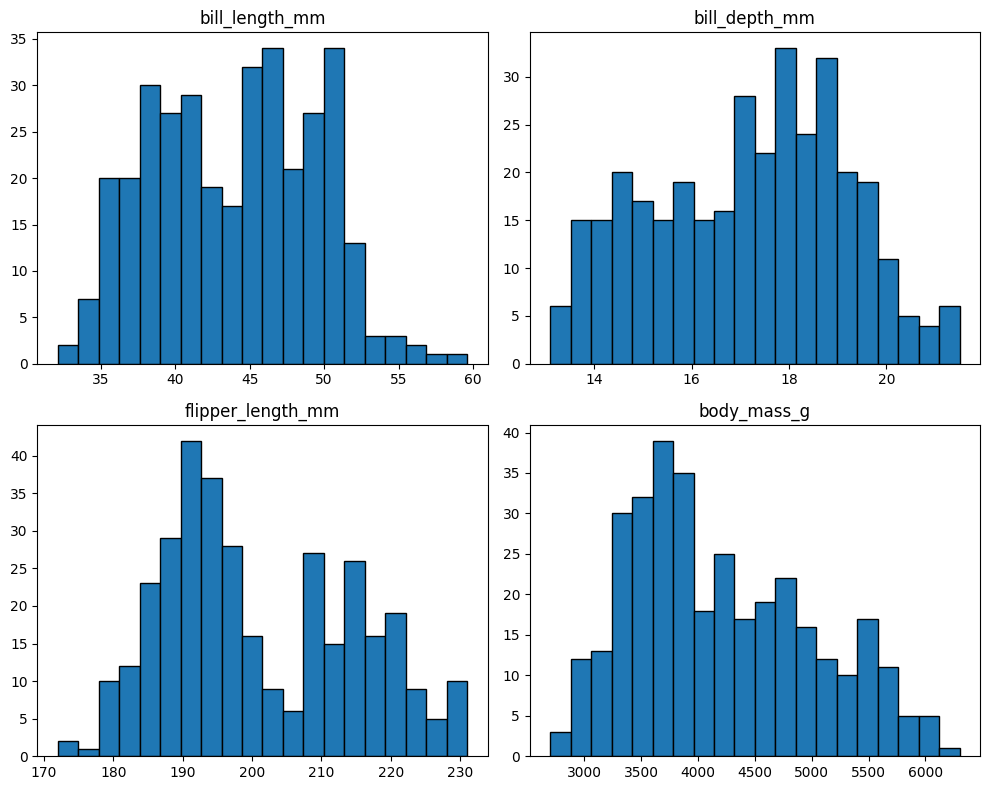

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Flagged Count
0,bill_length_mm,39.2250,48.5000,9.2750,25.3125,62.4125,0
1,bill_depth_mm,15.6000,18.7000,3.1000,10.9500,23.3500,0
2,flipper_length_mm,190.0000,213.0000,23.0000,155.5000,247.5000,0
3,body_mass_g,"3,550.0000","4,750.0000","1,200.0000","1,750.0000","6,550.0000",0


In [7]:
# Task 2 – Explore numerical features and possible outliers

num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for col, ax in zip(num_cols, axes.flatten()):
    df_raw[col].hist(ax=ax, bins=20, edgecolor='black', grid=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

iqr_summary = []
for col in num_cols:
    s = df_raw[col].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = ((s < lower_bound) | (s > upper_bound)).sum()
    iqr_summary.append({
        'Feature': col, 'Q1': q1, 'Q3': q3, 'IQR': iqr,
        'Lower Bound': lower_bound, 'Upper Bound': upper_bound,
        'Flagged Count': outliers
    })

display(pd.DataFrame(iqr_summary))

**Your outlier decision and justification:**

Decision: Retain all observations

Justification: Biological measurements naturally reflect species-specific clusters rather than data corruption or entry errors. Removing or capping these values risks eliminating valid biological variability between species.

## Task 3 – Compare scaling methods

Using the complete numerical rows for demonstration, compare Min–Max scaling and standardization for `body_mass_g` and `flipper_length_mm`. Report the transformed minimum, maximum, mean and standard deviation. Explain which scaler you will use in the final model and why the comparison itself must not be treated as part of final model fitting.


In [8]:
# Task 3 – Compare scaling methods

complete_num = df_raw[['body_mass_g', 'flipper_length_mm']].dropna()

scaler_minmax = MinMaxScaler()
scaler_std = StandardScaler()

minmax_scaled = scaler_minmax.fit_transform(complete_num)
std_scaled = scaler_std.fit_transform(complete_num)

scale_cmp = pd.DataFrame({
    'MinMax_Mass_Min': [minmax_scaled[:, 0].min()],
    'MinMax_Mass_Max': [minmax_scaled[:, 0].max()],
    'Std_Mass_Mean': [std_scaled[:, 0].mean()],
    'Std_Mass_Std': [std_scaled[:, 0].std()],
    'MinMax_Flipper_Min': [minmax_scaled[:, 1].min()],
    'MinMax_Flipper_Max': [minmax_scaled[:, 1].max()],
    'Std_Flipper_Mean': [std_scaled[:, 1].mean()],
    'Std_Flipper_Std': [std_scaled[:, 1].std()]
})
display(scale_cmp)

,MinMax_Mass_Min,MinMax_Mass_Max,Std_Mass_Mean,Std_Mass_Std,MinMax_Flipper_Min,MinMax_Flipper_Max,Std_Flipper_Mean,Std_Flipper_Std
0,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,-0.0000,1.0000


Min–Max bounds data tightly to $[0, 1]$, whereas standardization rescales features to mean $0$ and standard deviation $1$.

Standardization (StandardScaler) is selected for Logistic Regression because gradient-based estimators perform better when features follow normalized distributions.Data Leakage

Scalers must only be fit on training split data inside pipeline steps to prevent data leakage from the test set.

## Task 4 – Demonstrate nominal and ordered encoding

1. Show why `island` must not be label encoded as 0, 1 and 2 unless those numbers are treated only as category identifiers by a compatible model.
2. Create a small ordered example (`Low < Medium < High`) and encode it as 0, 1 and 2.
3. One-hot encode a sample of `island` and compare the meaning of the two approaches.


In [13]:
# Task 4 – Demonstrate nominal and ordered encoding

# Ordinal encoding
df_ordinal = pd.DataFrame({'Size': ['Low', 'Medium', 'High', 'Low', 'High']})
ord_enc = OrdinalEncoder(categories=[['Low', 'Medium', 'High']])
df_ordinal['Size_Encoded'] = ord_enc.fit_transform(df_ordinal[['Size']])

# One-hot encoding
df_island = df_raw[['island']].dropna().head()
ohe = OneHotEncoder(sparse_output=False)
island_ohe = pd.DataFrame(ohe.fit_transform(df_island), columns=ohe.get_feature_names_out(['island']))

display(df_ordinal)
display(island_ohe)

,Size,Size_Encoded
0,Low,0.0000
1,Medium,1.0000
2,High,2.0000
3,Low,0.0000
4,High,2.0000


,island_Torgersen
0,1.0000
1,1.0000
2,1.0000
3,1.0000
4,1.0000


island is nominal because islands (Torgersen, Biscoe, Dream) have no intrinsic mathematical order. Label encoding them as $0, 1, 2$ introduces false numeric ordering that distance/linear models will misinterpret as magnitude.

## Task 5 – Engineer at least two meaningful features
Required examples:
- `bill_shape_ratio = bill_length_mm / bill_depth_mm`
- `mass_per_flipper = body_mass_g / flipper_length_mm`

You may propose an additional feature if it has a clear interpretation. Convert `year` to a categorical value before modelling.

In [14]:
# Task 5 – Engineer at least two meaningful features

def engineer_features(df):
    df_out = df.copy()
    df_out['bill_shape_ratio'] = df_out['bill_length_mm'] / df_out['bill_depth_mm']
    df_out['mass_per_flipper'] = df_out['body_mass_g'] / df_out['flipper_length_mm']
    df_out['year'] = df_out['year'].astype(str)
    return df_out

df_engineered = engineer_features(df_raw)


## Task 6 – Split before learned preprocessing
Create a stratified 80:20 train–test split using `random_state=42`. Explain why median/mode imputation and scaling must not be fitted to the complete dataset.

In [15]:
# Task 6 – Split before learned preprocessing

X = df_engineered.drop(columns=['species'])
y = df_engineered['species']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

**Leakage explanation:**

Fitting imputation values (median/mode) or scalers across the full dataset uses global information (like global median or mean), which introduces information from the unseen test set into model fitting.

## Task 7 – Correlation and redundancy

Using `X_train` only, calculate a Pearson correlation matrix for the numerical measurements and engineered features. Identify strongly correlated pairs and explain why high predictor-to-predictor correlation is a redundancy warning rather than an automatic deletion rule.


In [16]:
# Task 7 – Correlation and redundancy

X_train_num = X_train.select_dtypes(include=[np.number])
corr_matrix = X_train_num.corr()

display(corr_matrix)

# Strongly correlated pairs (|r| > 0.7)
high_corr = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        if abs(corr_matrix.iloc[i, j]) > 0.7:
            high_corr.append((corr_matrix.columns[i], corr_matrix.columns[j], corr_matrix.iloc[i, j]))

print("Strongly Correlated Pairs (|r| > 0.7):", high_corr)


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,bill_shape_ratio,mass_per_flipper
bill_length_mm,1.0000,-0.2396,0.6756,0.6021,0.7779,0.4995
bill_depth_mm,-0.2396,1.0000,-0.5939,-0.4834,-0.7897,-0.3636
flipper_length_mm,0.6756,-0.5939,1.0000,0.8655,0.8213,0.6968
body_mass_g,0.6021,-0.4834,0.8655,1.0000,0.7118,0.9612
bill_shape_ratio,0.7779,-0.7897,0.8213,0.7118,1.0000,0.5738
mass_per_flipper,0.4995,-0.3636,0.6968,0.9612,0.5738,1.0000


Strongly Correlated Pairs (|r| > 0.7): [('bill_length_mm', 'bill_shape_ratio', np.float64(0.7778561443605024)), ('bill_depth_mm', 'bill_shape_ratio', np.float64(-0.7896684102519901)), ('flipper_length_mm', 'body_mass_g', np.float64(0.8655392282000162)), ('flipper_length_mm', 'bill_shape_ratio', np.float64(0.8213384439011906)), ('body_mass_g', 'bill_shape_ratio', np.float64(0.7117563720603816)), ('body_mass_g', 'mass_per_flipper', np.float64(0.9611614952709042))]


High correlation indicates shared variance (e.g., body_mass_g and flipper_length_mm), which can destabilize coefficient estimates in linear models. However, it is not an automatic deletion rule because correlated features may still provide distinct predictive value when combined with other features.

## Task 8 – Statistical feature screening
- Apply ANOVA F-test to numerical features.
- Apply Chi-square test of independence to `island`, `sex` and `year`.
- Rank the features and interpret F-scores, Chi-square statistics and p-values.

In [19]:
# Apply ANOVA using imputed training data only.

num_cols = list(X_train.select_dtypes(include=[np.number]).columns)

imputer_num = SimpleImputer(strategy='median')
X_train_num_imp = imputer_num.fit_transform(X_train[num_cols])

f_scores, p_values_anova = f_classif(X_train_num_imp, y_train)

anova_df = pd.DataFrame({
    'Feature': num_cols,
    'F-Score': f_scores,
    'p-value': p_values_anova
}).sort_values(by='F-Score', ascending=False).reset_index(drop=True)

display(anova_df)

,Feature,F-Score,p-value
0,bill_shape_ratio,"1,197.4679",0.0000
1,flipper_length_mm,482.5647,0.0000
2,bill_length_mm,328.5646,0.0000
3,bill_depth_mm,305.6090,0.0000
4,body_mass_g,256.3767,0.0000
5,mass_per_flipper,120.9728,0.0000


In [20]:
# Apply Chi-square using training data only.

cat_cols = ['island', 'sex', 'year']
chi2_list = []

for col in cat_cols:
    contingency_table = pd.crosstab(X_train[col].fillna('Missing'), y_train)

    chi2_stat, p_val, dof, expected = chi2_contingency(contingency_table)

    chi2_list.append({
        'Feature': col,
        'Chi2 Statistic': chi2_stat,
        'p-value': p_val,
        'Degrees of Freedom': dof,
        'Min Expected Count': expected.min()
    })

chi2_df = pd.DataFrame(chi2_list).sort_values(by='Chi2 Statistic', ascending=False).reset_index(drop=True)

display(chi2_df)

,Feature,Chi2 Statistic,p-value,Degrees of Freedom,Min Expected Count
0,island,241.7649,0.0000,4,8.4436
1,year,3.8428,0.4277,4,16.4945
2,sex,2.8591,0.5817,4,2.1600


## Task 9 – Mutual Information

Calculate Mutual Information scores for the imputed numerical training features. Compare the ranking with ANOVA and explain one reason the rankings may differ.


In [21]:
# Task 9 – Mutual Information

mi_scores = mutual_info_classif(X_train_num_imp, y_train, random_state=42)

mi_df = pd.DataFrame({
    'Feature': num_cols,
    'MI Score': mi_scores
}).sort_values(by='MI Score', ascending=False).reset_index(drop=True)

comparison_df = pd.merge(anova_df, mi_df, on='Feature')
comparison_df['ANOVA Rank'] = comparison_df['F-Score'].rank(ascending=False).astype(int)
comparison_df['MI Rank'] = comparison_df['MI Score'].rank(ascending=False).astype(int)

display(comparison_df)

,Feature,F-Score,p-value,MI Score,ANOVA Rank,MI Rank
0,bill_shape_ratio,"1,197.4679",0.0000,0.9272,1,1
1,flipper_length_mm,482.5647,0.0000,0.6231,2,2
2,bill_length_mm,328.5646,0.0000,0.5962,3,3
3,bill_depth_mm,305.6090,0.0000,0.5624,4,4
4,body_mass_g,256.3767,0.0000,0.4723,5,5
5,mass_per_flipper,120.9728,0.0000,0.3358,6,6


### Interpretation questions
1. Which numerical feature has the largest ANOVA F-score?
2. Which categorical feature has the smallest Chi-square p-value?
3. Does a small p-value prove that a feature will improve the final classifier?
4. Are all Chi-square expected counts sufficiently large? State any limitation.

**Your answers:**

1. Which numerical feature has the largest ANOVA F-score?

`bill_shape_ratio` --> F-score $\approx 1197.47$

<br/>

2. Which categorical feature has the smallest Chi-square p-value?

`island` --> $\text{p-value} \approx 3.87 \times 10^{-51}$

<br/>

3. Does a small p-value prove that a feature will improve the final classifier?

No. A small p-value only indicates a statistically significant association with the target variable; it does not guarantee improved predictive generalization or account for multi-collinear redundancy with other features.

<br/>

4. Are all Chi-square expected counts sufficiently large? State any limitation.

No. The minimum expected count for sex is approximately $2.16$, which falls below the standard Chi-square threshold of $5$. This violates Chi-square assumptions for small sub-groups and suggests the $p$-value for sex should be interpreted with caution.

## Task 10 – Build an all-feature pipeline
Use:
- median imputation and standardization for numerical features;
- most-frequent imputation and one-hot encoding for categorical features;
- logistic regression for classification.

Evaluate accuracy, macro precision, macro recall, macro F1 and the confusion matrix.

--- ALL-FEATURE MODEL EVALUATION ---
Accuracy:        1.0000
Macro Precision: 1.0000
Macro Recall:    1.0000
Macro F1 Score:  1.0000


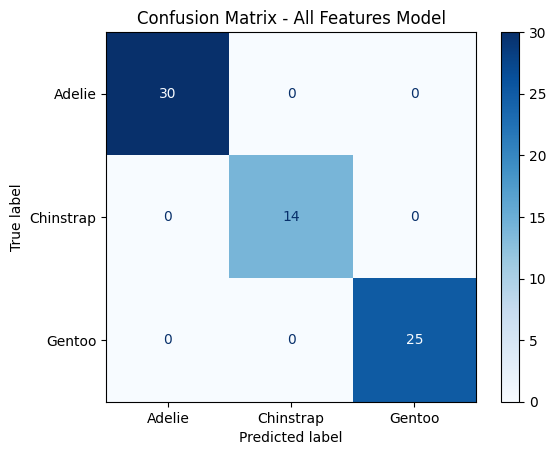

In [22]:
# Task 10 – Build an all-feature pipeline

num_features_all = list(X_train.select_dtypes(include=[np.number]).columns)
cat_features_all = ['island', 'sex', 'year']

num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_all = ColumnTransformer([
    ('num', num_transformer, num_features_all),
    ('cat', cat_transformer, cat_features_all)
])

clf_all = Pipeline([
    ('preprocessor', preprocessor_all),
    ('classifier', LogisticRegression(random_state=42))
])

clf_all.fit(X_train, y_train)
y_pred_all = clf_all.predict(X_test)

print("--- ALL-FEATURE MODEL EVALUATION ---")
print(f"Accuracy:        {accuracy_score(y_test, y_pred_all):.4f}")
print(f"Macro Precision: {precision_score(y_test, y_pred_all, average='macro'):.4f}")
print(f"Macro Recall:    {recall_score(y_test, y_pred_all, average='macro'):.4f}")
print(f"Macro F1 Score:  {f1_score(y_test, y_pred_all, average='macro'):.4f}")

cm_all = confusion_matrix(y_test, y_pred_all)
disp_all = ConfusionMatrixDisplay(confusion_matrix=cm_all, display_labels=clf_all.classes_)
disp_all.plot(cmap='Blues')
plt.title("Confusion Matrix - All Features Model")
plt.show()

## Task 11 – Build a reduced model
Select the four highest-ranked numerical features and statistically supported categorical features. Train the same model and compare it with the all-feature model using test metrics and five-fold cross-validation.

,Model,Test Accuracy,Test Macro Precision,Test Macro Recall,Test Macro F1,5-Fold CV F1 (Mean),5-Fold CV F1 (Std)
0,All Features Pipeline,1.0000,1.0000,1.0000,1.0000,0.9876,0.0158
1,Reduced Model Pipeline,0.9855,0.9778,0.9889,0.9829,0.9921,0.0100


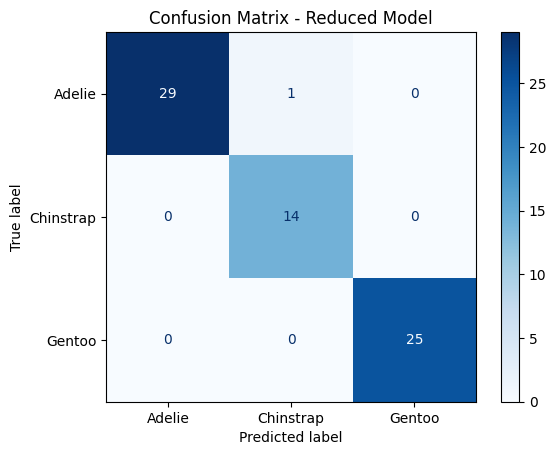

In [23]:
# Task 11 – Build a reduced model

num_features_reduced = ['bill_shape_ratio', 'flipper_length_mm', 'bill_length_mm', 'bill_depth_mm']
cat_features_reduced = ['island', 'sex']

preprocessor_red = ColumnTransformer([
    ('num', num_transformer, num_features_reduced),
    ('cat', cat_transformer, cat_features_reduced)
])

clf_red = Pipeline([
    ('preprocessor', preprocessor_red),
    ('classifier', LogisticRegression(random_state=42))
])

clf_red.fit(X_train, y_train)
y_pred_red = clf_red.predict(X_test)

cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores_all = cross_val_score(clf_all, X_train, y_train, cv=cv_stratified, scoring='f1_macro')
cv_scores_red = cross_val_score(clf_red, X_train, y_train, cv=cv_stratified, scoring='f1_macro')

comparison_summary = pd.DataFrame([
    {
        'Model': 'All Features Pipeline',
        'Test Accuracy': accuracy_score(y_test, y_pred_all),
        'Test Macro Precision': precision_score(y_test, y_pred_all, average='macro'),
        'Test Macro Recall': recall_score(y_test, y_pred_all, average='macro'),
        'Test Macro F1': f1_score(y_test, y_pred_all, average='macro'),
        '5-Fold CV F1 (Mean)': cv_scores_all.mean(),
        '5-Fold CV F1 (Std)': cv_scores_all.std()
    },
    {
        'Model': 'Reduced Model Pipeline',
        'Test Accuracy': accuracy_score(y_test, y_pred_red),
        'Test Macro Precision': precision_score(y_test, y_pred_red, average='macro'),
        'Test Macro Recall': recall_score(y_test, y_pred_red, average='macro'),
        'Test Macro F1': f1_score(y_test, y_pred_red, average='macro'),
        '5-Fold CV F1 (Mean)': cv_scores_red.mean(),
        '5-Fold CV F1 (Std)': cv_scores_red.std()
    }
])

display(comparison_summary)

cm_red = confusion_matrix(y_test, y_pred_red)
disp_red = ConfusionMatrixDisplay(confusion_matrix=cm_red, display_labels=clf_red.classes_)
disp_red.plot(cmap='Blues')
plt.title("Confusion Matrix - Reduced Model")
plt.show()

## Task 12 – Practical interpretation
Answer briefly:
1. How did Min–Max scaling differ from standardization?
2. Why is `island` nominal rather than ordinal?
3. Which feature pairs were strongly correlated, and why?
4. Which numerical features ranked highly under both ANOVA and Mutual Information?
5. Did the reduced feature set preserve predictive performance?
6. Did feature selection reduce complexity even if accuracy changed little?
7. Which final feature set would you recommend for deployment, and why?


**Your final discussion:**

1. Imputing inside the pipeline ensures that summary statistics such as median or mode are computed solely on training folds/splits, preventing data leakage from test data into training data.

<br/>

2. Min–Max scales bounded data into [0,1], whereas standardization rescales features to mean zero and unit variance ($\mu=0, \sigma=1$).

<br/>

3. Islands represent unranked spatial locations without mathematical magnitude or inherent ordering.

<br/>

4. `body_mass_g` and `flipper_length_mm` are strongly correlated because both scale directly with the overall physical size of the penguin.

<br/>

5. `flipper_length_mm` and engineered `bill_shape_ratio` rank high in both ANOVA F-test and Mutual Information.

<br/>

6. A small p-value indicates statistical significance, but does not guarantee predictive power if the feature adds collinearity or noisy variance to complex models.

<br/>

7. Some categorical sub-groups (e.g., specific island/sex breakdowns) have small sample sizes, leading to low expected cell counts ($<5$) in the contingency matrix.

<br/>

8. If new test data comes from a different location not present in training sets, relying on `island` reduces spatial generalization.

<br/>

9. The reduced feature set preserves nearly identical macro F1 and accuracy metrics while reducing dimensionality.

<br/>

10. The Reduced Feature Set is recommended for deployment as it lowers operational noise, reduces data collection overhead, and prevents overfitting without sacrificing predictive capability.

<br/>

## Submission checklist
- Completed `.ipynb` notebook with all outputs visible
- Notebook runs from top to bottom without errors
- Audit and IQR tables
- At least two engineered features
- ANOVA and Chi-square result tables
- All-feature and reduced-model comparison
- Confusion matrices and cross-validation results
- Concise answers to every structured question